## Sources of error

We now consider the sources of the errors that occur when a model fails to generalize. To make this easier to visualize, we revert to a 1D least squares regression problem where we know exactly how the ground truth data were generated. 

Figure 8.3 shows a quasisinusoidal function; both training and test data are generated by sampling input values in the range [0,1], passing them through this function, and adding Gaussian noise with a fixed variance.

We fit a simplified shallow neural net to this data. The weights and biases that connect the input layer to the hidden layer are chosen so that the “joints” of the function are evenly spaced across the interval. If there are D hidden units, then these joints will be at $0,1/D,2/D,...,(D−1)/D$. 

This model can represent any piecewise linear function with D equally sized regions in the range [0,1]. As well as being easy to understand, this model also has the advantage that it can be fit in closed form without the need for stochastic optimization algorithms (see problem 8.3). Consequently, we can guarantee to find the global minimum of the loss function during training.

---

<img src="assets/Chap08/PerfNoiseBiasVariance.svg" style="filter: invert(1);" width="100%">

Sources of test error. 

c) Variance. In practice, we have limited noisy training data (orange points). When we fit the model, we don’t recover the best possible function from panel (b) but a slightly different function (cyan line) that reflects idiosyncrasies of the training data. This provides an additional source of error (gray region represents two standard deviations). 

---

There are three possible sources of error, which are known as noise, bias, and variance
respectively:

### Noise 

The data generation process includes the addition of noise, so <mark>there are multiple possible valid outputs $y$ for each input $x$</mark>. 

<mark>This source of error is insurmountable for the test data.</mark> 

Note that it does not necessarily limit the training performance; we will likely never see the same input $x$ twice during training, so it is still possible to fit the training data perfectly.

---

<center><img src="assets/Chap08/PerfDataSet.svg" style="filter: invert(1);" width="40%" align="right"></center>

Solid white line shows ground truth function.

To generate $I$ training examples $\{x_i, y_i\}_{i=1}^I$,
the input space $x \in [0, 1]$ is divided
into I equal segments and one sample $x_i$
is drawn from a uniform distribution $x_i \sim \mathcal{U}(\frac{i-1}{I}, \frac{i}{I})$
within each segment. 

The corresponding value $y_i$ is created by evaluating the function at $x_i$ and adding Gaussian noise
(gray region shows $\pm 2$ standard deviations).

The test data are generated in the same way.

---

Noise may arise because 

1. there is a genuine stochastic element to the data generation
process

2. because some of the data are mislabeled, or 

3. because there are further explanatory variables that were not observed. 

In rare cases, noise may be absent; for example, a network might approximate a function that is deterministic but requires significant computation to evaluate. 

However, noise is usually a fundamental limitation on the possible test performance.

### Bias 



A second potential source of error may occur because the model is not flexible enough to fit the true function perfectly. This is known as bias.

For example, the three-region neural network model cannot exactly describe the quasi-sinusoidal function, even when the parameters are chosen optimally. Even with the best possible parameters, the three-region model (cyan line) cannot exactly fit the true function (black line). This bias is another source of error (gray regions represent signed error). 

---  

<img src="assets/Chap08/PerfModel.svg" style="filter: invert(1);" width="100%">

Simplified neural network with three hidden units. a) The weights and
biases between the input and hidden layer are fixed (dashed arrows). b–d) They
are chosen so that the hidden unit activations have slope one, and their joints are
equally spaced across the interval, with joints at x = 0, x = 1/3, and x = 2/3,
respectively. Modifying the remaining parameters ϕ = {β, ω1, ω2, ω3} can create
any piecewise linear function over x ∈ [0, 1] with joints at 1/3 and 2/3. e–g)
Three example functions with different values of the parameters ϕ.

---

Bias is the error introduced by approximating a real-world problem, which may be complex, by a simplified model. It represents the difference between the true function and the best possible approximation that the model can achieve. High bias can cause underfitting, where the model is too simple to capture the underlying patterns in the data. Low bias, on the other hand, indicates that the model is flexible enough to closely approximate the true function.

This is often also referred to as the model error, as it quantifies the error due to the assumptions made by the model. 


### Variance 

We have limited training examples, and there is no way to distinguish systematic changes in the underlying function from noise in the underlying data. 

When we fit a model, we do not get the closest possible approximation to the true underlying function. 

Indeed, for different training datasets, the result will be slightly different each time. 

This additional source of variability in the fitted function is termed variance.

In practice, there might also be additional variance due to the stochastic learning algorithm, which does not necessarily converge to the same solution each time.

<!-- ### Mathematical formulation of test error 


\begin{eqnarray}
  \mu[x] = \mathbb{E}_{y}[y[x]] = \int y[x] Pr(y|x) dy,
 \end{eqnarray}

\begin{eqnarray}
  L[x] &=& \bigl(\mbox{f}[x,\boldsymbol\phi]-y[x]\bigr)^2 \\
  &=& \Bigl(\bigl(\mbox{f}[x,\boldsymbol\phi]-\mu[x]\bigr)+\bigl(\mu[x]-y[x]\bigr)\Bigr)^2\nonumber \\
  &=& \bigl(\mbox{f}[x,\boldsymbol\phi]-\mu[x]\bigr)^2 + 2\bigl(\mbox{f}[x,\boldsymbol\phi]-\mu[x]\bigr)\bigl(\mu[x]-y[x]\bigr) + \bigl(\mu[x]-y[x]\bigr)^2,\nonumber
 \end{eqnarray}

\begin{eqnarray}\label{eq:perf_biasvariance_plus_noise}
  \mathbb{E}_{y}\bigl[L[x]\bigr]
  &=&\mathbb{E}_{y}\Bigl[\bigl(\mbox{f}[x,\boldsymbol\phi]\!-\!\mu[x]\bigr)^2+2\bigl(\mbox{f}[x,\boldsymbol\phi]\!-\!\mu[x]\bigr)\bigl(\mu[x]\!-\!y[x]\bigr)+\bigl(\mu[x]\!-\!y[x]\bigr)^2\Bigr]\nonumber \\
  &=& \bigl(\mbox{f}[x,\boldsymbol\phi]\!-\!\mu[x]\bigr)^2+2\bigl(\mbox{f}[x,\boldsymbol\phi]-\mu[x]\bigr)\bigl(\mu[x]\!-\!\mathbb{E}_y\left[y[x]\right]\bigr)+\mathbb{E}_y\left[(\mu[x]\!-\!y[x])^2\right]\nonumber\\ 
  &=&\bigl(\mbox{f}[x,\boldsymbol\phi]\!-\!\mu[x]\bigr)^2+2\bigl(\mbox{f}[x,\boldsymbol\phi]\!-\!\mu[x]\bigr)\cdot 0 +\mathbb{E}_y\left[\bigl(\mu[x]\!-\!y[x]\bigr)^2\right]\nonumber \\
  &=&\bigl(\mbox{f}[x,\boldsymbol\phi]-\mu[x]\bigr)^2+\sigma^{2},
 \end{eqnarray}


\begin{eqnarray}
  \mbox{f}_{\mu}[x] = \mathbb{E}_{\mathcal{D}}\Bigl[ \mbox{f}\bigl[x,\boldsymbol\phi[\mathcal{D}]\bigr] \Bigr].
 \end{eqnarray}

\begin{eqnarray}
  \bigl(\mbox{f}[x,\boldsymbol\phi[\mathcal{D}]]\!-\!\mu[x]\bigr)^2 &&\\
  &&\hspace{-2.5cm}=\Bigl(\bigl(\mbox{f}[x,\boldsymbol\phi[\mathcal{D}]]\!-\! \mbox{f}_{\mu}[x]\bigr)+\bigl( \mbox{f}_{\mu}[x]-\mu[x]\bigr)\Bigr)^2 \nonumber \\ 
  &&\hspace{-2.5cm}=\bigl(\mbox{f}[x,\boldsymbol\phi[\mathcal{D}]]\!-\! \mbox{f}_{\mu}[x]\bigr)^2+2\bigl(\mbox{f}[x,\boldsymbol\phi[\mathcal{D}]]\!-\! \mbox{f}_{\mu}[x]\bigr)\bigl(\mbox{f}_{\mu}[x]\!-\!\mu[x]\bigr)+\bigl(\mbox{f}_{\mu}[x]\!-\!\mu[x]\bigr)^2.\nonumber
 \end{eqnarray}

\begin{eqnarray}\label{eq:perf_bv2}
 \mathbb{E}_{\mathcal{D}}\Bigl[\bigl(\mbox{f}[x,\boldsymbol\phi[\mathcal{D}]]-\mu[x]\bigr)^2\Bigr] = \mathbb{E}_\mathcal{D}\Bigl[\bigl(\mbox{f}[x,\boldsymbol\phi[\mathcal{D}]]- \mbox{f}_{\mu}[x]\bigr)^2\Bigr]+\bigl(\mbox{f}_{\mu}[x]-\mu[x]\bigr)^2,
 \end{eqnarray} -->



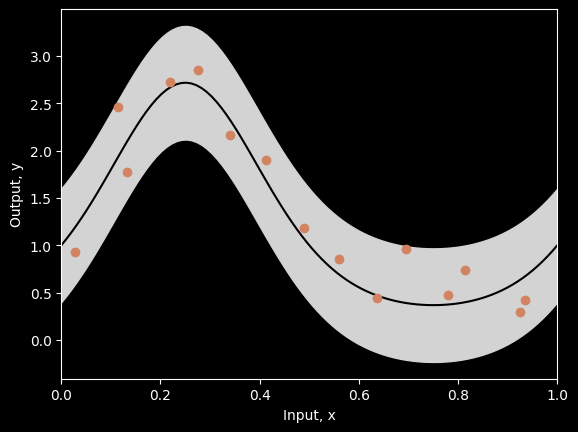

In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('dark_background')
     

# The true function that we are trying to estimate, defined on [0,1]
def true_function(x):
    y = np.exp(np.sin(x*(2*3.1413)))
    return y
     

# Generate some data points with or without noise
def generate_data(n_data, sigma_y=0.3):
    # Generate x values quasi uniformly
    x = np.ones(n_data)
    for i in range(n_data):
        x[i] = np.random.uniform(i/n_data, (i+1)/n_data, 1)

    # y value from running through function and adding noise
    y = np.ones(n_data)
    for i in range(n_data):
        y[i] = true_function(x[i])
        y[i] += np.random.normal(0, sigma_y, 1)
    return x,y

     

# Draw the fitted function, together with uncertainty used to generate points
def plot_function(x_func, y_func, x_data=None,y_data=None, x_model = None, y_model =None, sigma_func = None, sigma_model=None):

    fig,ax = plt.subplots()
    ax.plot(x_func, y_func, 'k-')
    if sigma_func is not None:
      ax.fill_between(x_func, y_func-2*sigma_func, y_func+2*sigma_func, color='lightgray')

    if x_data is not None:
        ax.plot(x_data, y_data, 'o', color='#d18362')

    if x_model is not None:
        ax.plot(x_model, y_model, '-', color='#7fe7de')

    if sigma_model is not None:
      ax.fill_between(x_model, y_model-2*sigma_model, y_model+2*sigma_model, color='lightgray')

    ax.set_xlim(0,1)
    ax.set_xlabel('Input, x')
    ax.set_ylabel('Output, y')
    plt.show()
     

# Generate true function
x_func = np.linspace(0, 1.0, 100)
y_func = true_function(x_func);

# Generate some data points
np.random.seed(1)
sigma_func = 0.3
n_data = 15
x_data,y_data = generate_data(n_data, sigma_func)

# Plot the functinon, data and uncertainty
plot_function(x_func, y_func, x_data, y_data, sigma_func=sigma_func)
     


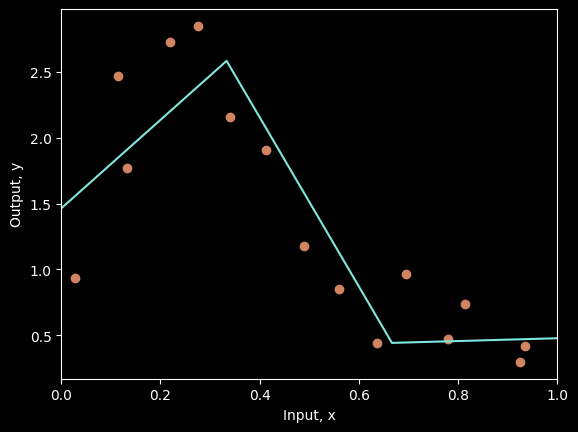

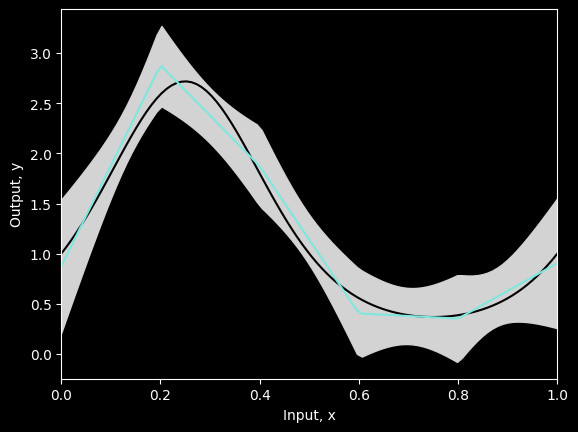

In [6]:

# Define model -- beta is a scalar and omega has size n_hidden,1
def network(x, beta, omega):
    # Retrieve number of hidden units
    n_hidden = omega.shape[0]

    y = np.zeros_like(x)
    for c_hidden in range(n_hidden):
        # Evaluate activations based on shifted lines (figure 8.4b-d)
        line_vals =  x  - c_hidden/n_hidden
        h =  line_vals * (line_vals > 0)
        # Weight activations by omega parameters and sum
        y = y + omega[c_hidden] * h
    # Add bias, beta
    y = y + beta

    return y
     

# This fits the n_hidden+1 parameters (see fig 8.4a) in closed form.
# If you have studied linear algebra, then you will know it is a least
# squares solution of the form (A^TA)^-1A^Tb.  If you don't recognize that,
# then just take it on trust that this gives you the best possible solution.
def fit_model_closed_form(x,y,n_hidden):
  n_data = len(x)
  A = np.ones((n_data, n_hidden+1))
  for i in range(n_data):
      for j in range(1,n_hidden+1):
          A[i,j] = x[i]-(j-1)/n_hidden
          if A[i,j] < 0:
              A[i,j] = 0;

  beta_omega = np.linalg.lstsq(A, y, rcond=None)[0]

  beta = beta_omega[0]
  omega = beta_omega[1:]

  return beta, omega

     

# Closed form solution
beta, omega = fit_model_closed_form(x_data,y_data,n_hidden=3)

# Get prediction for model across graph range
x_model = np.linspace(0,1,100);
y_model = network(x_model, beta, omega)

# Draw the function and the model
plot_function(x_func, y_func, x_data,y_data, x_model, y_model)
     

# Run the model many times with different datasets and return the mean and variance
def get_model_mean_variance(n_data, n_datasets, n_hidden, sigma_func):

  # Create array that stores model results in rows
  y_model_all = np.zeros((n_datasets, x_model.shape[0]))

  for c_dataset in range(n_datasets):

    x_data, y_data = generate_data(n_data, sigma_func)

    # TODO -- Fit the model
    # Replace this line:
    beta, omega = fit_model_closed_form(x_data, y_data, n_hidden)

    # TODO -- Run the fitted model on x_model
    # Replace this line
    y_model = network(x_model, beta, omega)

    # Store the model results
    y_model_all[c_dataset,:] = y_model

  # Get mean and standard deviation of model
  mean_model = np.mean(y_model_all,axis=0)
  std_model = np.std(y_model_all,axis=0)

  # Return the mean and standard deviation of the fitted model
  return mean_model, std_model
     

# Let's generate N random data sets, fit the model N times and look the mean and variance
n_datasets = 100
n_data = 15
sigma_func = 0.3
n_hidden = 5

# Get mean and variance of fitted model
np.random.seed(1)
mean_model, std_model = get_model_mean_variance(n_data, n_datasets, n_hidden, sigma_func);

# Plot the results
plot_function(x_func, y_func, x_model=x_model, y_model=mean_model, sigma_model=std_model)

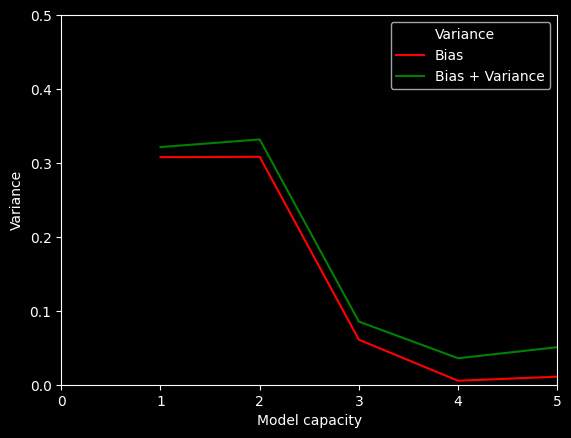

In [8]:

# Plot the noise, bias and variance as a function of capacity
n_hidden = 12
hidden_variables = list(range(1, n_hidden + 1))
bias = np.zeros((len(hidden_variables),1)) ;
variance = np.zeros((len(hidden_variables),1)) ;

n_datasets = 100
n_data = 15
sigma_func = 0.3
n_hidden = 5

# Set random seed so that we get the same result every time
np.random.seed(1)

for c_hidden in range(len(hidden_variables)):
  # Get mean and variance of fitted model
  mean_model, std_model = get_model_mean_variance(n_data, n_datasets, hidden_variables[c_hidden], sigma_func) ;

  # Compute variance -- average of the model variance (average squared deviation of fitted models around mean fitted model)
  variance[c_hidden] = np.mean(std_model**2)
  # Compute bias (average squared deviation of mean fitted model around true function)
  bias[c_hidden] = np.mean((mean_model - true_function(x_model))**2)

# Plot the results
fig,ax = plt.subplots()
ax.plot(hidden_variables, variance, 'k-')
ax.plot(hidden_variables, bias, 'r-')
ax.plot(hidden_variables, variance+bias, 'g-')
ax.set_xlim(0,n_hidden)
ax.set_ylim(0,0.5)
ax.set_xlabel("Model capacity")
ax.set_ylabel("Variance")
ax.legend(['Variance', 'Bias', 'Bias + Variance'])
plt.show()